# Datset description
## Health annual inflation vs Nationwide anual inflation 2022 - 2026

**Source**: [Banco de la República](https://suameca.banrep.gov.co/estadisticas-economicas/tablasPreconstruidas)

# Code
## Imports

In [16]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", lambda x: "%.2f" % x)

## Load data

In [17]:
path = "./data/health_inflation.csv"
path_2 = "./data/inflation_monthly.csv"

df = pd.read_csv(
    path,
    header=0,
    names=["year", "period_label", "date", "scope_member", "value"],
    usecols=["date", "value"],
    parse_dates=["date"],
    date_format="%Y-%m-%d",
    decimal=",",
)

df_f = pd.read_csv(path_2, parse_dates=["date"], date_format="%Y-%m-%d")

## Clean data

In [21]:
print("Total:\n", df_f.head(10))
print("Health:\n", df.head(10))

Nationwide:
         date  value
0 2022-01-01   6.94
1 2022-02-01   8.01
2 2022-03-01   8.53
3 2022-04-01   9.23
4 2022-05-01   9.07
5 2022-06-01   9.67
6 2022-07-01  10.21
7 2022-08-01  10.84
8 2022-09-01  11.44
9 2022-10-01  12.22
Health:
         date  value
0 2022-01-01   4.68
1 2022-02-01   5.29
2 2022-03-01   5.98
3 2022-04-01   6.45
4 2022-05-01   6.81
5 2022-06-01   7.03
6 2022-07-01   7.68
7 2022-08-01   8.21
8 2022-09-01   8.24
9 2022-10-01   8.45


## Plot

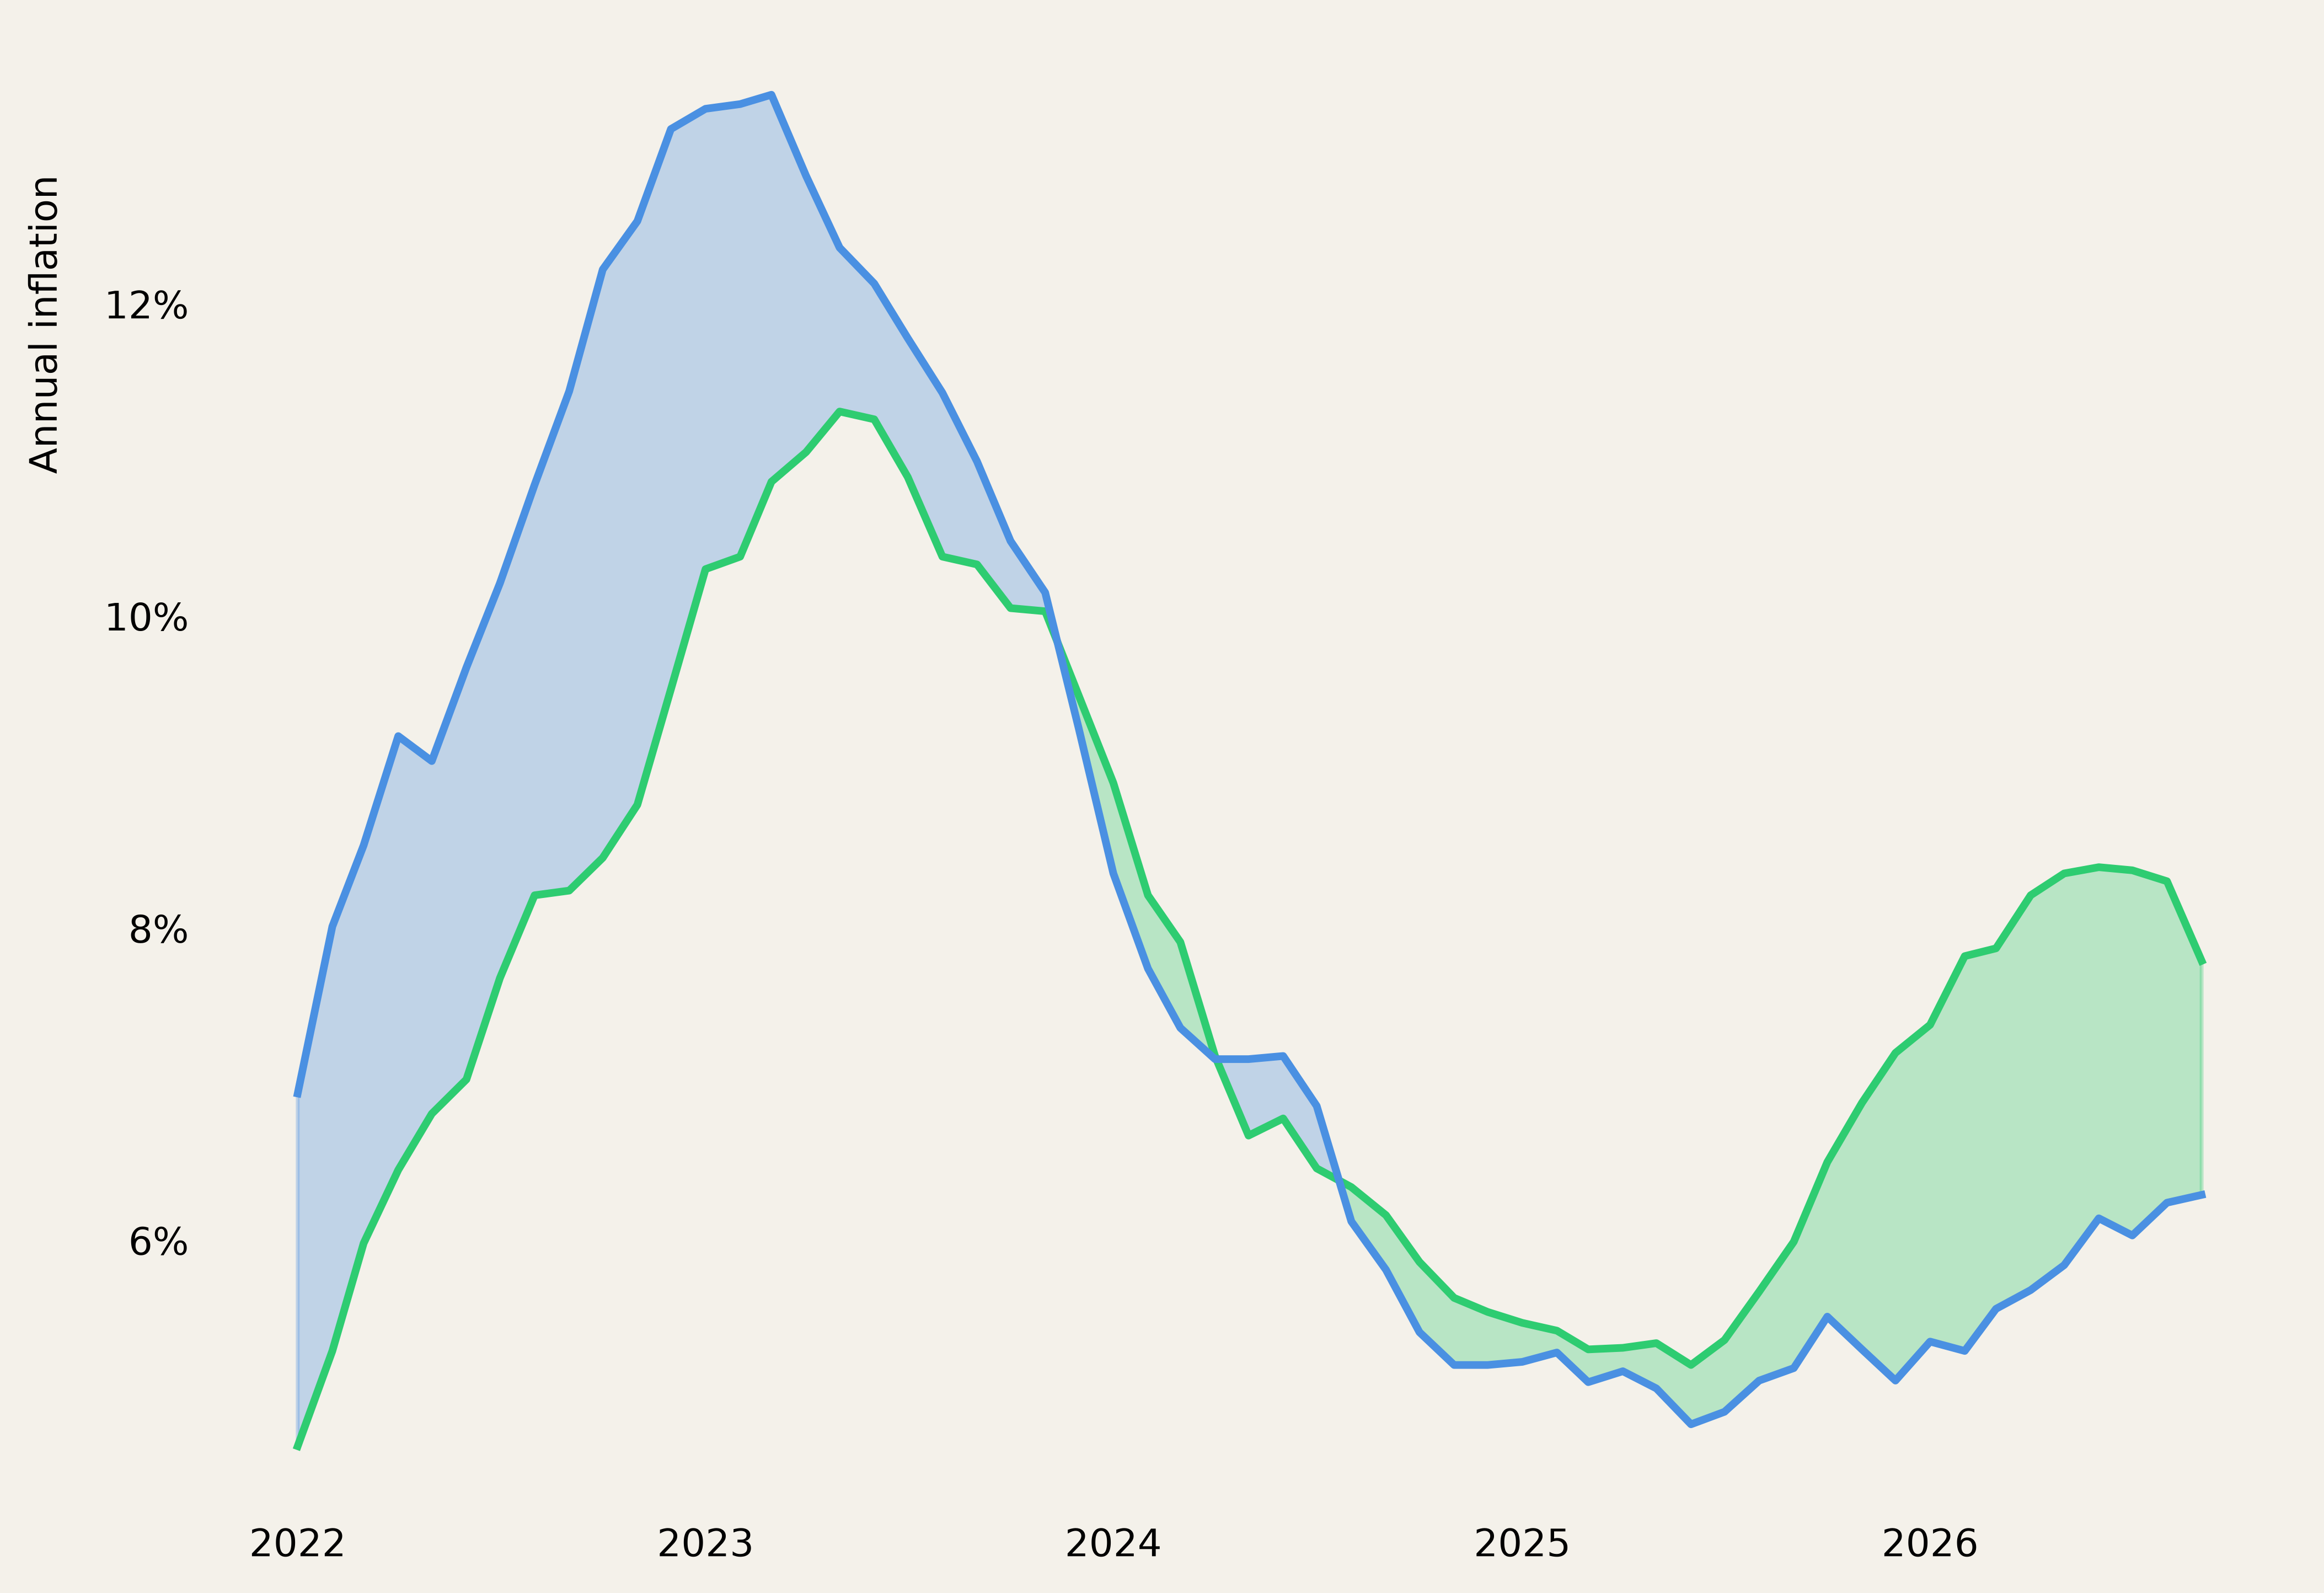

In [29]:
background = "#F4F1EA"
blue = "#4a90e2"
green = "#2ecc71"

fig, ax = plt.subplots(figsize=(9.8, 7.0), dpi=500)
fig.patch.set_facecolor(background)
ax.patch.set_facecolor(background)

plt.plot(df["date"], df["value"], linewidth=2, color=green)
plt.plot(df_f["date"], df_f["value"], linewidth=2, color=blue)

for side in ["top", "bottom", "left", "right"]:
    plt.gca().spines[side].set_visible(False)

for axis in ["y", "x"]:
    plt.tick_params(axis=axis, length=0)

plt.ylabel("Annual inflation", labelpad=10, fontsize=10, y=0.8)

plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0f}%"))

plt.fill_between(
    df["date"],
    df["value"],
    df_f["value"],
    where=(df["value"] > df_f["value"]),
    color=green,
    alpha=0.3,
    interpolate=True
)

plt.fill_between(
    df["date"],
    df["value"],
    df_f["value"],
    where=(df["value"] < df_f["value"]),
    color=blue,
    alpha=0.3,
    interpolate=True
)

plt.show()